In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import pandas as pd
import numpy as np
import random

# Импорт sklearn для классических алгоритмов ML
from sklearn.model_selection import train_test_split, StratifiedKFold  # разделение данных и кросс-валидация
from sklearn.dummy import DummyClassifier  # наивный классификатор для бейслайна
from sklearn.compose import ColumnTransformer  # трансформация разных столбцов по-разному
from sklearn.pipeline import Pipeline  # создание пайплайнов обработки
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, HashingVectorizer  # векторизация текста
from sklearn.linear_model import LogisticRegression  # логистическая регрессия
from sklearn.tree import DecisionTreeClassifier  # дерево решений
from sklearn.ensemble import RandomForestClassifier  # случайный лес
from sklearn.base import clone  # клонирование моделей
from lightgbm import LGBMClassifier  # градиентный бустинг

# Пользовательские модули
from helper import *  # вспомогательные функции
from plots import *   # функции визуализации
from nlp import *     # функции обработки естественного языка
from transformers import *  # функции для работы с трансформерами

In [4]:
SEED = 42 
np.random.seed(SEED)  
random.seed(SEED)     

In [5]:
df = pd.read_csv('data/data_preprocessed.csv')

In [6]:
X = df['cleaned_text']
y = df['label']

In [7]:
all_baseline_metrics = []# Список для хранения итоговых Pydantic-метрик всех экспериментов

In [8]:
wooden_models = [
    ("Decision Tree", DecisionTreeClassifier(max_depth=15, random_state=42)),
    ("Random Forest", RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)),
    ("LightGBM", LGBMClassifier(n_estimators=100, learning_rate=0.1, random_state=42, n_jobs=-1))
]

#  1. CountVectorizer

---  CountVectorizer (Без очистки стоп-слов) ---
Оценка Decision Tree (CountVocab, No StopWords)...


<Figure size 1500x600 with 0 Axes>

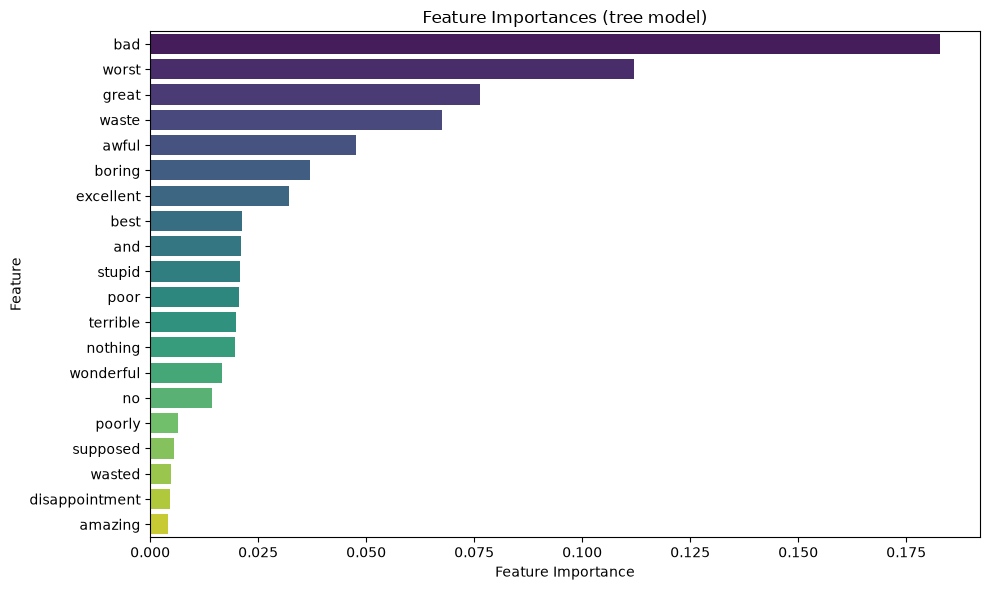

Оценка Random Forest (CountVocab, No StopWords)...


<Figure size 1500x600 with 0 Axes>

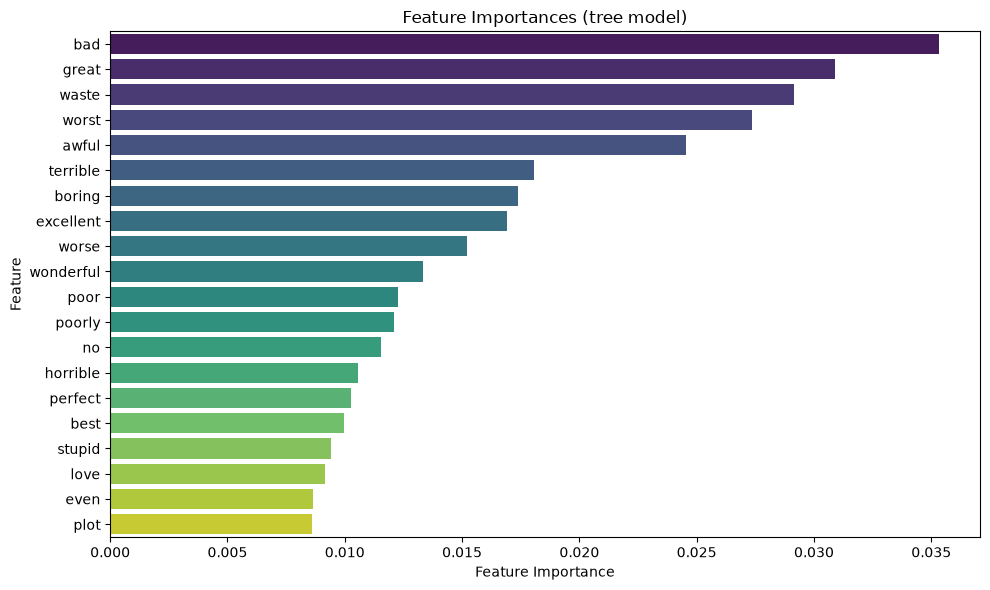

Оценка LightGBM (CountVocab, No StopWords)...
[LightGBM] [Info] Number of positive: 16666, number of negative: 16667
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.292756 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 25406
[LightGBM] [Info] Number of data points in the train set: 33333, number of used features: 5000
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.499985 -> initscore=-0.000060
[LightGBM] [Info] Start training from score -0.000060
[LightGBM] [Info] Number of positive: 16667, number of negative: 16666
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.265049 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 25441
[LightGBM] [Info] Number of data points in the train set: 333

<Figure size 1500x600 with 0 Axes>

[LightGBM] [Info] Number of positive: 25000, number of negative: 25000
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.304895 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 27223
[LightGBM] [Info] Number of data points in the train set: 50000, number of used features: 5000
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


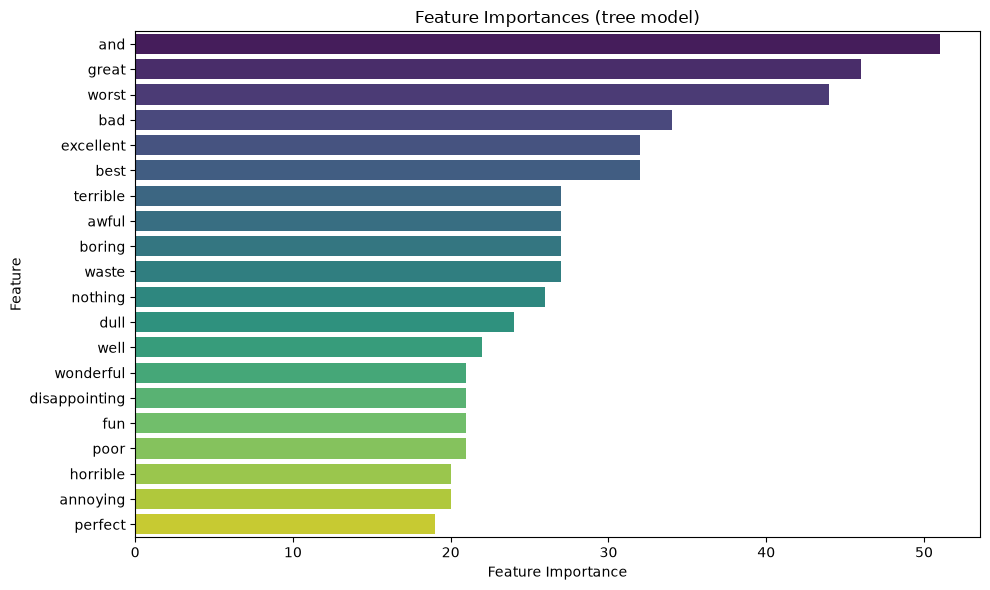

In [10]:
print("---  CountVectorizer (Без очистки стоп-слов) ---")
vectorizer_1 = CountVectorizer(max_features=5000, dtype=np.float32)

for model_name, model in wooden_models:
    full_name = f'{model_name} (CountVocab, No StopWords)'
    print(f"Оценка {full_name}...")

    metrics = train_evaluate_model_cv(
        model=model,
        model_name=full_name,
        X=X,
        y=y,
        preprocessor=vectorizer_1,
        cv=3,
        task_type='classification',
        plot_feature_importance=True
    )
    metrics.name = full_name
    all_baseline_metrics.append(metrics)

### 1.1 CountVectorizer + Удаление стоп-слов


--- CountVectorizer + Удаление стоп-слов ---
Оценка Decision Tree (CountVocab + StopWords Removal)...


<Figure size 1500x600 with 0 Axes>

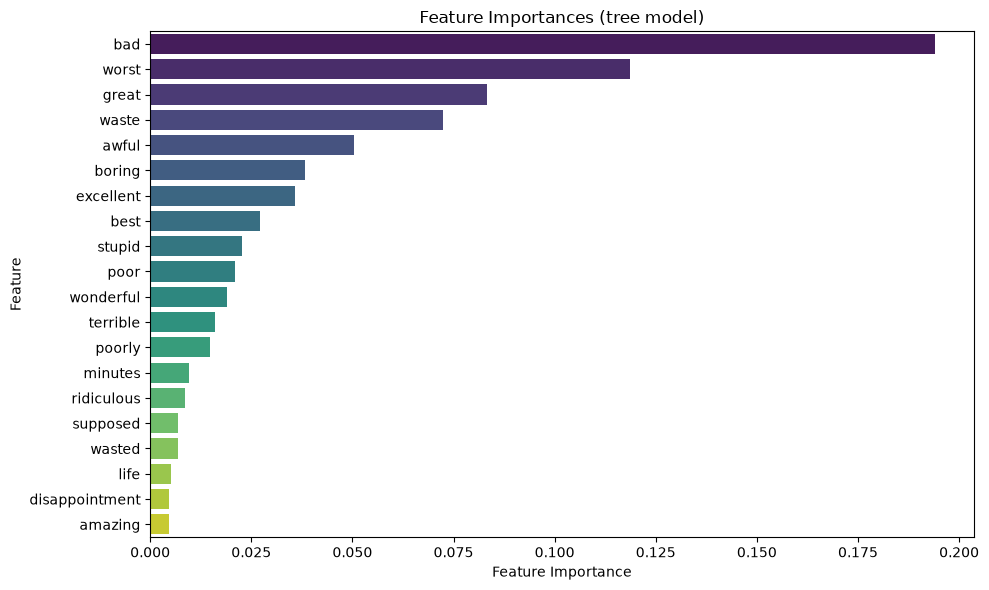

Оценка Random Forest (CountVocab + StopWords Removal)...


<Figure size 1500x600 with 0 Axes>

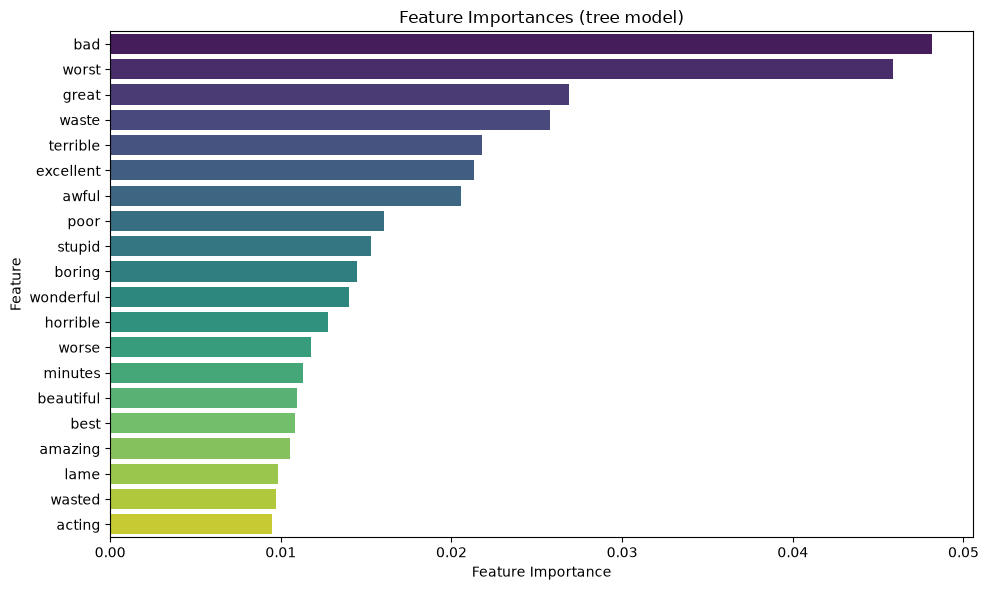

Оценка LightGBM (CountVocab + StopWords Removal)...
[LightGBM] [Info] Number of positive: 16666, number of negative: 16667
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.216174 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 23916
[LightGBM] [Info] Number of data points in the train set: 33333, number of used features: 5000
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.499985 -> initscore=-0.000060
[LightGBM] [Info] Start training from score -0.000060
[LightGBM] [Info] Number of positive: 16667, number of negative: 16666
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.247770 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 23947
[LightGBM] [Info] Number of data points in the train se

<Figure size 1500x600 with 0 Axes>

[LightGBM] [Info] Number of positive: 25000, number of negative: 25000
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.284598 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 25741
[LightGBM] [Info] Number of data points in the train set: 50000, number of used features: 5000
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


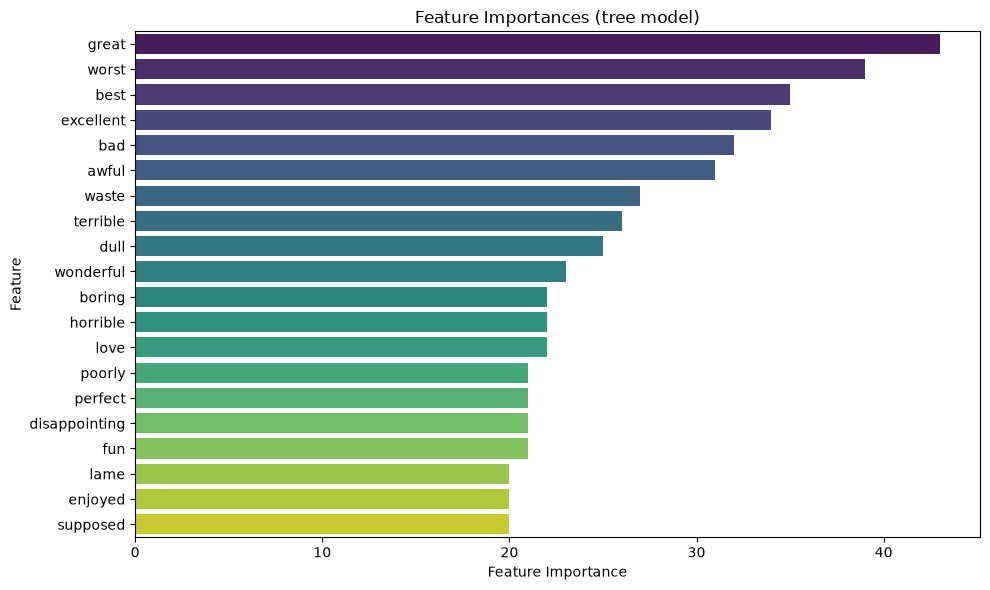

In [12]:
print("\n--- CountVectorizer + Удаление стоп-слов ---")
vectorizer_2 = CountVectorizer(max_features=5000, stop_words='english', dtype=np.float32)

for model_name, model in wooden_models:
    full_name = f"{model_name} (CountVocab + StopWords Removal)"
    print(f"Оценка {full_name}...")
    
    metrics = train_evaluate_model_cv(
        model=model,
        model_name=full_name,
        X=X,
        y=y,
        preprocessor=vectorizer_2,
        cv=3,
        task_type="classification",
        plot_feature_importance=True
    )
    metrics.name = full_name
    all_baseline_metrics.append(metrics)

### 1.2 CountVocab топ-100 важных токенов

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import FunctionTransformer

print("Токенизация текстов для отбора признаков...")
df['tokens'] = df['cleaned_text'].apply(tokenize_tiktoken)
X_tokens = df['tokens'] 

Токенизация текстов для отбора признаков...


In [10]:
# Создаем цепочку трансформации признаков
text_preprocessor = Pipeline([
    ('selector', NgramFeatureSelector(top_k=100)),
    # Преобразуем список токенов обратно в строку, чтобы CountVectorizer мог его прочитать
    ('stringifier', FunctionTransformer(lambda docs: [" ".join(doc)for doc in docs], validate=False)),
    ('vectorizer', CountVectorizer(dtype=np.float32))
    ])

Оценка Decision Tree (Top-100 Tokens Selector)...


<Figure size 1500x600 with 0 Axes>

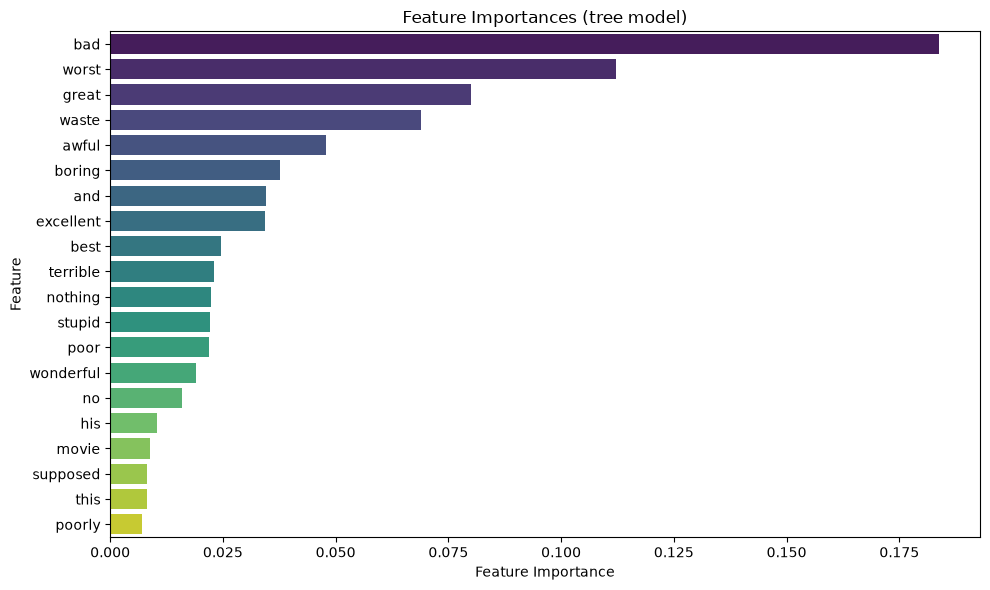

Оценка Random Forest (Top-100 Tokens Selector)...


<Figure size 1500x600 with 0 Axes>

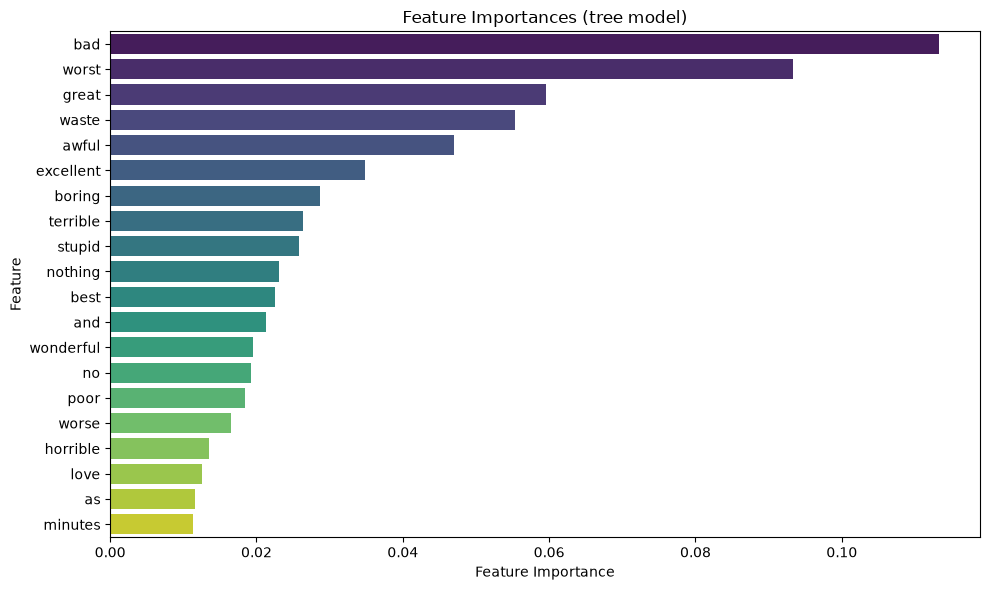

Оценка LightGBM (Top-100 Tokens Selector)...
[LightGBM] [Info] Number of positive: 16666, number of negative: 16667
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.063777 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 813
[LightGBM] [Info] Number of data points in the train set: 33333, number of used features: 98
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.499985 -> initscore=-0.000060
[LightGBM] [Info] Start training from score -0.000060
[LightGBM] [Info] Number of positive: 16667, number of negative: 16666
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007736 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 842
[LightGBM] [Info] Number of data points in the train set: 33333, num

<Figure size 1500x600 with 0 Axes>

[LightGBM] [Info] Number of positive: 25000, number of negative: 25000
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.102991 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 878
[LightGBM] [Info] Number of data points in the train set: 50000, number of used features: 98
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


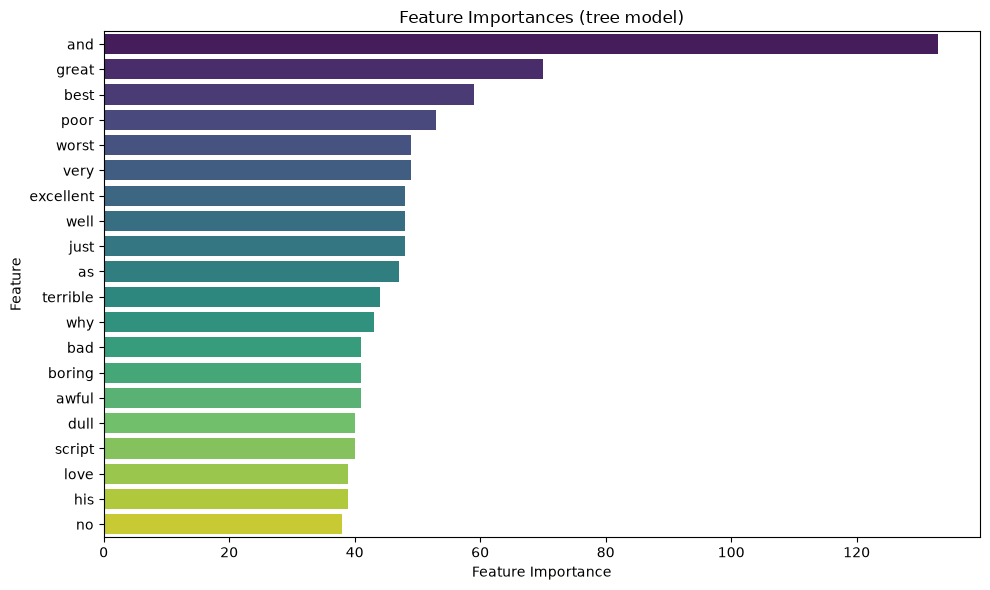

In [11]:
for model_name, model in wooden_models:
    full_name = f"{model_name} (Top-100 Tokens Selector)"
    print(f"Оценка {full_name}...")
    
    metrics = train_evaluate_model_cv(
        model=model,
        model_name=full_name,
        X=X_tokens,
        y=y,
        preprocessor=text_preprocessor,
        cv=3,
        task_type="classification",
        plot_feature_importance=True
    )
    metrics.name = full_name
    all_baseline_metrics.append(metrics)

# 2. TfidfVectorizer

--- TfidfVectorizer (Без очистки стоп-слов) ---
Оценка Decision Tree (TF-IDF, No StopWords)...


<Figure size 1500x600 with 0 Axes>

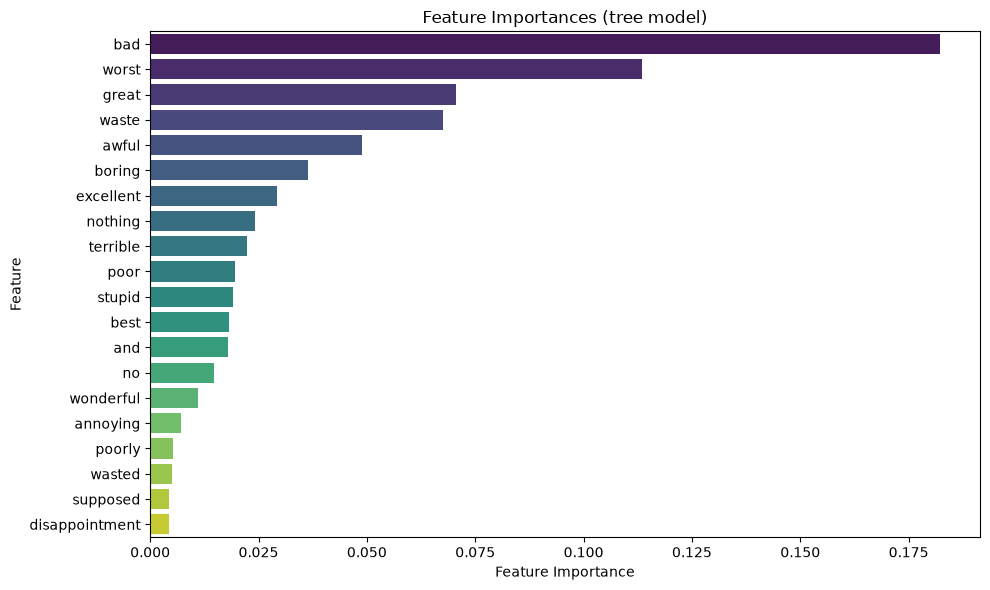

Оценка Random Forest (TF-IDF, No StopWords)...


<Figure size 1500x600 with 0 Axes>

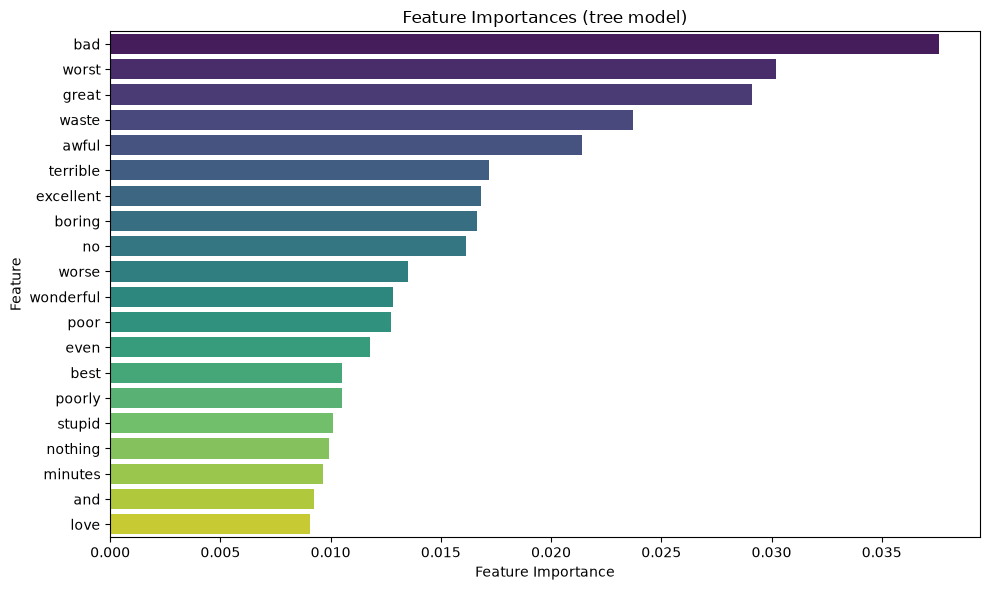

Оценка LightGBM (TF-IDF, No StopWords)...
[LightGBM] [Info] Number of positive: 16666, number of negative: 16667
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.463949 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 561020
[LightGBM] [Info] Number of data points in the train set: 33333, number of used features: 5000
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.499985 -> initscore=-0.000060
[LightGBM] [Info] Start training from score -0.000060
[LightGBM] [Info] Number of positive: 16667, number of negative: 16666
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.461923 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 561351
[LightGBM] [Info] Number of data points in the train set: 33333, number of used features: 5000
[LightGBM] [Info] [binary:BoostF

<Figure size 1500x600 with 0 Axes>

[LightGBM] [Info] Number of positive: 25000, number of negative: 25000
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.632782 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 705376
[LightGBM] [Info] Number of data points in the train set: 50000, number of used features: 5000
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


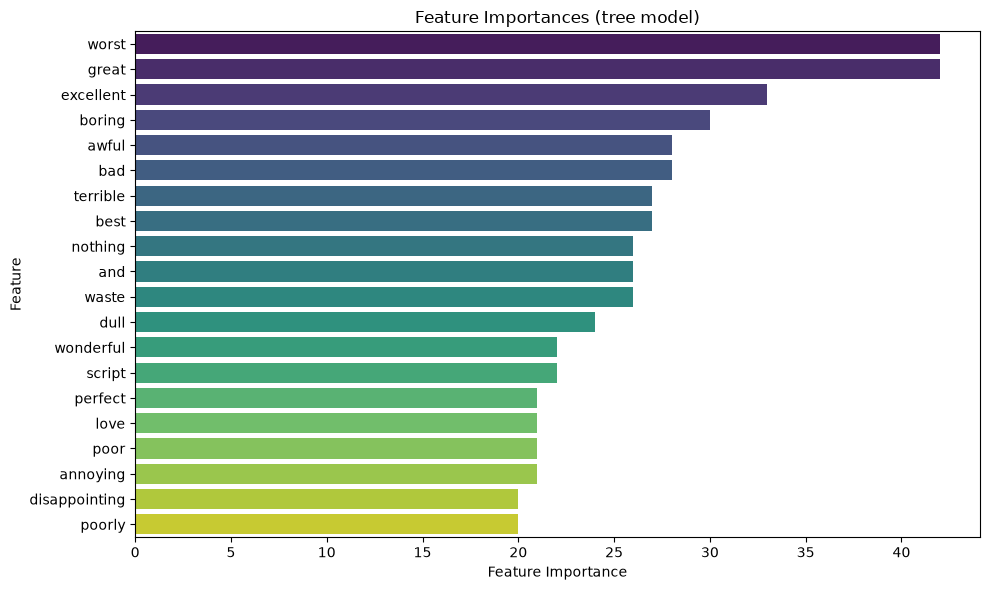

In [12]:
print("--- TfidfVectorizer (Без очистки стоп-слов) ---")
vectorizer_4 = TfidfVectorizer(max_features=5000)

for model_name, model in wooden_models:
    full_name = f"{model_name} (TF-IDF, No StopWords)"
    print(f"Оценка {full_name}...")
    
    metrics = train_evaluate_model_cv(
        model=model,
        model_name=full_name,
        X=X,
        y=y,
        preprocessor=vectorizer_4,
        cv=3,
        task_type="classification",
        plot_feature_importance=True
    )
    metrics.name = full_name
    all_baseline_metrics.append(metrics)

### 2.1 TfidfVectorizer + Удаление стоп-слов


--- TfidfVectorizer + Удаление стоп-слов ---
Оценка Decision Tree (TF-IDF + StopWords Removal)...


<Figure size 1500x600 with 0 Axes>

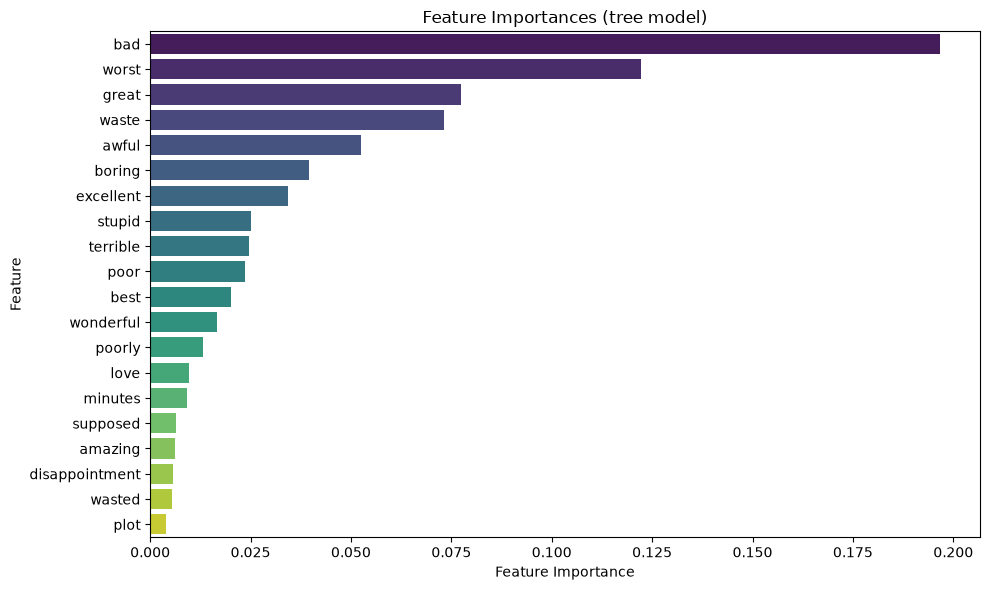

Оценка Random Forest (TF-IDF + StopWords Removal)...


<Figure size 1500x600 with 0 Axes>

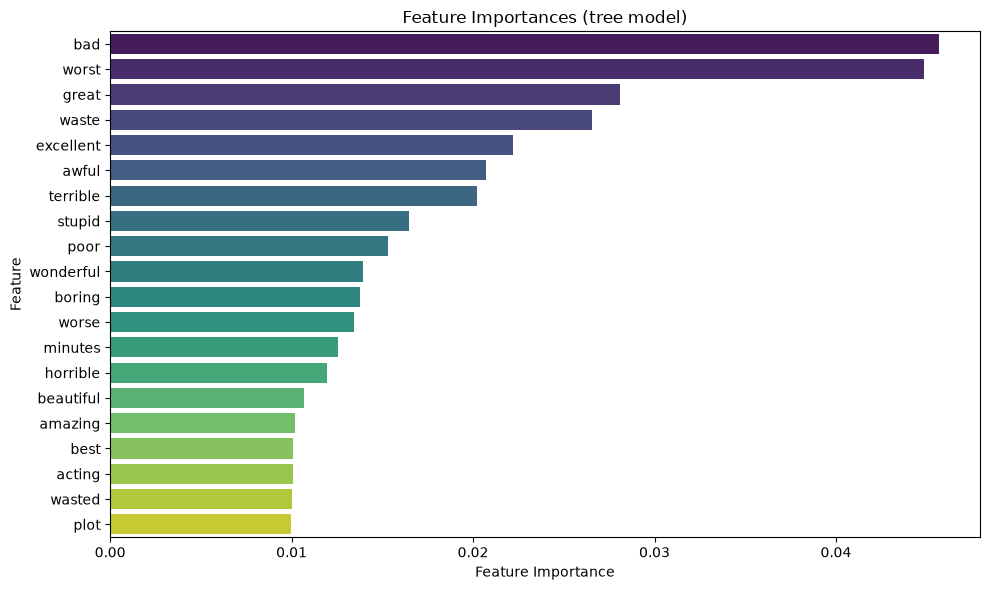

Оценка LightGBM (TF-IDF + StopWords Removal)...
[LightGBM] [Info] Number of positive: 16666, number of negative: 16667
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.379617 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 506954
[LightGBM] [Info] Number of data points in the train set: 33333, number of used features: 5000
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.499985 -> initscore=-0.000060
[LightGBM] [Info] Start training from score -0.000060
[LightGBM] [Info] Number of positive: 16667, number of negative: 16666
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.362809 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 507362
[LightGBM] [Info] Number of data points in the train set: 33333, number of used features: 4999
[LightGBM] [Info] [binary:

<Figure size 1500x600 with 0 Axes>

[LightGBM] [Info] Number of positive: 25000, number of negative: 25000
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.564990 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 652427
[LightGBM] [Info] Number of data points in the train set: 50000, number of used features: 5000
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


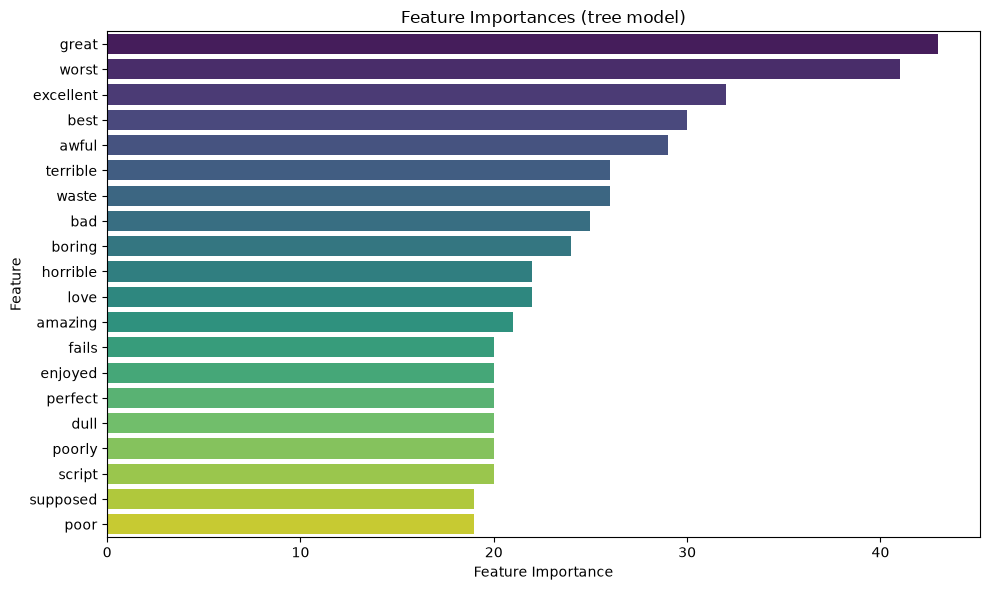

In [13]:
print("\n--- TfidfVectorizer + Удаление стоп-слов ---")
vectorizer_5 = TfidfVectorizer(max_features=5000, stop_words='english')

for model_name, model in wooden_models:
    full_name = f"{model_name} (TF-IDF + StopWords Removal)"
    print(f"Оценка {full_name}...")
    
    metrics = train_evaluate_model_cv(
        model=model,
        model_name=full_name,
        X=X,
        y=y,
        preprocessor=vectorizer_5,
        cv=3,
        task_type="classification",
        plot_feature_importance=True
    )
    metrics.name = full_name
    all_baseline_metrics.append(metrics)

#  Финальный сводный химап для всех древесных моделей


Построение глобального сравнительного хитмапа для всех бейзлайнов...


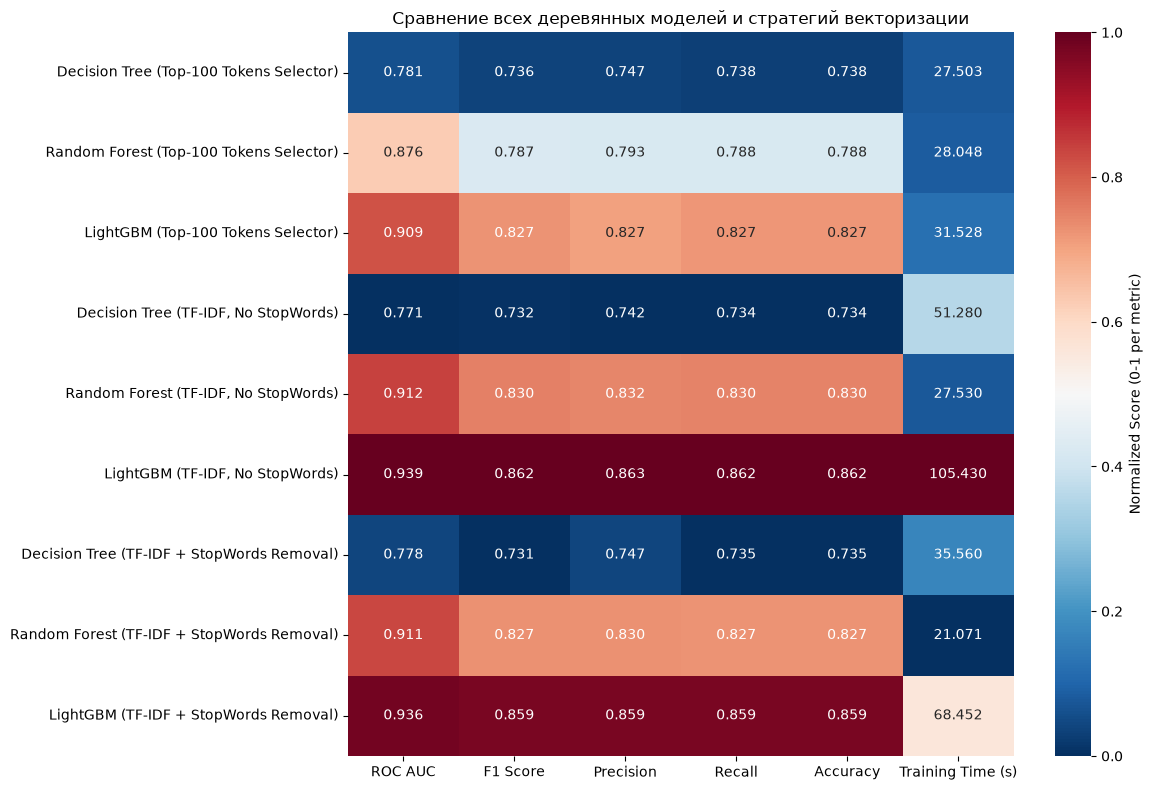

In [14]:
print("\nПостроение глобального сравнительного хитмапа для всех бейзлайнов...")
plot_metrics_heatmap(
    metrics=all_baseline_metrics, 
    title="Сравнение всех деревянных моделей и стратегий векторизации",
    figsize=(12, 8)
)

### Итоги исследования классических моделей (Baseline)

В ходе масштабного кросс-валидационного тестирования были проверены 3 древесные архитектуры (Decision Tree, Random Forest, LightGBM) в сочетании с различными стратегиями подготовки текста:

1. **LightGBM + TF-IDF (Без удаления стоп-слов) — Лучший классический бейзлайн**:
   * **Accuracy:** 86.2% | **ROC AUC:** 0.939
   * Модель показала пиковую точность за счет способности бустинга находить сложные нелинейные зависимости в непрерывных весах TF-IDF.

2. **Влияние отбора признаков (NgramFeatureSelector)**:
   * Кастомный фильтр Топ-100 токенов по ANOVA F-value позволил LightGBM удерживать точность на уровне **82.7%** всего на 100 признаках. Это подтверждает высокую репрезентативность отобранных токенов.

3. **Случайный лес против Одиночного дерева**:
   * Одиночные деревья решений (Decision Tree) сильно переобучались и застряли на уровне ~73% точности. Ансамблирование в Random Forest подняло планку до стабильных **83.0%**.